# 3.7 Artificial neural networks

A small multilayer perceptron (one hidden layer), gradient descent,
batches/epochs, and a look at overfitting/regularisation -- on the same
churn target/features/split as every other classification notebook.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## A perceptron / multilayer perceptron, and standardising inputs

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

mlp = MLPClassifier(hidden_layer_sizes=(8,), activation="relu", max_iter=2000,
                     random_state=0).fit(Xtr_s, ytr)
print("Test AUC:", round(roc_auc_score(yte, mlp.predict_proba(Xte_s)[:, 1]), 3))
print("Training loss curve has", len(mlp.loss_curve_), "points (one per epoch)")

Test AUC: 0.72
Training loss curve has 548 points (one per epoch)


Gradient descent needs standardised inputs to converge sensibly -- on raw,
differently-scaled features the loss surface is badly distorted and
training can stall or diverge, the same "sensitivity to scale" issue k-NN
had in 3.3.

## Optimisation with gradient descent: the loss curve

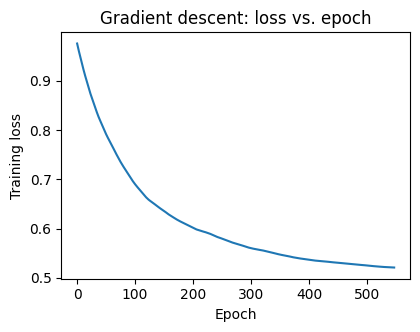

In [4]:
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.plot(mlp.loss_curve_)
ax.set_xlabel("Epoch"); ax.set_ylabel("Training loss"); ax.set_title("Gradient descent: loss vs. epoch")
plt.show()

## Activation functions, visually

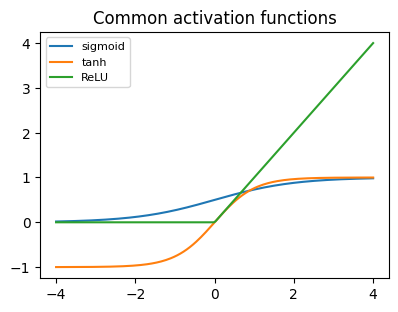

In [5]:
z = np.linspace(-4, 4, 200)
fns = {
    "sigmoid": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.clip(z, 0, None),
}
fig, ax = plt.subplots(figsize=(4.5, 3.2))
for name, vals in fns.items():
    ax.plot(z, vals, label=name)
ax.legend(fontsize=8); ax.set_title("Common activation functions")
plt.show()

## Avoiding overfitting: a wider/deeper net vs. regularisation

In [6]:
results = []
for hidden, alpha in [((4,), 0.0001), ((32, 16), 0.0001), ((32, 16), 0.05)]:
    m = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=2000, random_state=0).fit(Xtr_s, ytr)
    train_auc = roc_auc_score(ytr, m.predict_proba(Xtr_s)[:, 1])
    test_auc = roc_auc_score(yte, m.predict_proba(Xte_s)[:, 1])
    results.append({"hidden_layers": hidden, "alpha (L2 reg.)": alpha, "train_AUC": round(train_auc, 3), "test_AUC": round(test_auc, 3)})
pd.DataFrame(results)

,hidden_layers,alpha (L2 reg.),train_AUC,test_AUC
0,"(4,)",0.0001,0.761,0.765
1,"(32, 16)",0.0001,0.988,0.655
2,"(32, 16)",0.0500,0.976,0.650


A bigger network (more layers/units) can fit the training data better but
risks a growing train/test gap -- exactly the overfitting pattern from 3.5;
raising `alpha` (L2 weight regularisation, the NN analogue of ridge
regression from Section 2) pulls weights toward zero and can close that
gap back up.

In [7]:
clf = MLPClassifier(hidden_layer_sizes=(8,), activation="relu", max_iter=2000, random_state=0).fit(Xtr_s, ytr)

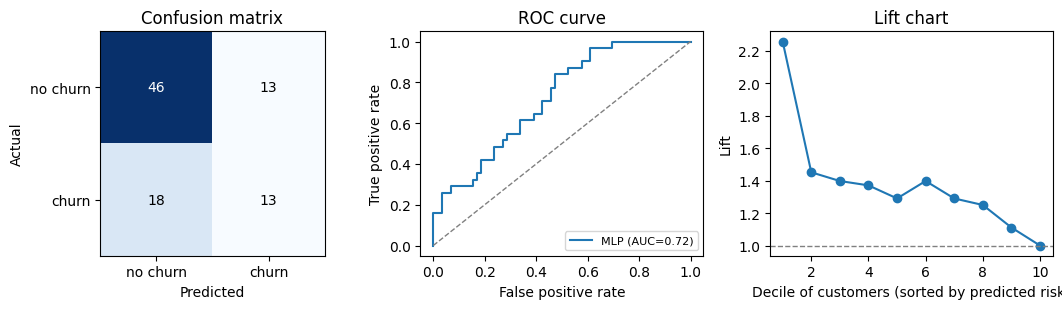

AUC: 0.72


In [8]:
y_pred = clf.predict(Xte_s)
y_score = clf.predict_proba(Xte_s)[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="MLP")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: this closes Section 3 -- seven techniques, the exact same
churn target/features/split throughout, so the AUC/lift numbers across all
seven notebooks are a fair, apples-to-apples comparison.